# Testes de Regressão Linear no WineQT

Este notebook aplica a regressão linear em uma perspectiva de diagnóstico e validação do conjunto de dados.

Objetivos:
- avaliar se uma relação linear entre variáveis físicas/químicas e qualidade é razoável;
- verificar qualidade dos resíduos;
- documentar limitações do uso da regressão em um problema de qualidade binária/ordinal.


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Carregamento do dataset
wine = pd.read_csv('../data/WineQT.csv')

# Meta de qualidade para regressão contínua
X = wine[[col for col in wine.columns if col not in {'quality', 'Id'}]]
y = wine['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('shape_X_train=', X_train.shape)
print('shape_X_test=', X_test.shape)


shape_X_train= (914, 11)
shape_X_test= (229, 11)


R² = 0.3171
MAE = 0.4773
RMSE = 0.6165


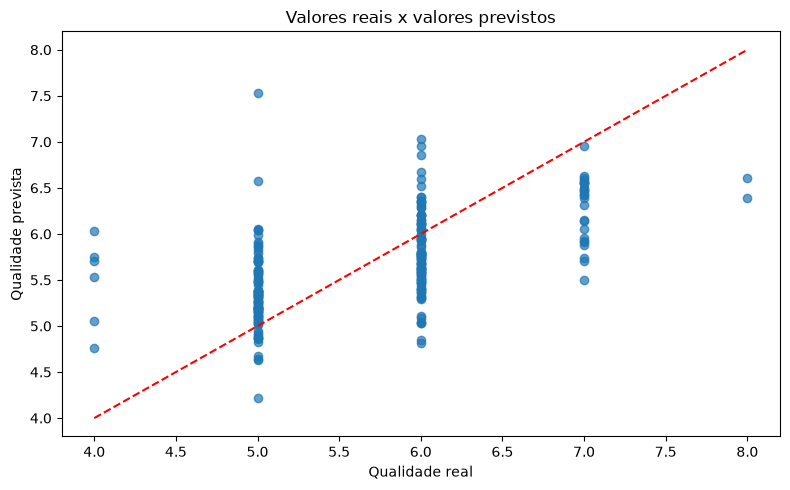

In [5]:
# Modelo linear simples
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

r2 = r2_score(y_test, pred)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))

print(f'R² = {r2:.4f}')
print(f'MAE = {mae:.4f}')
print(f'RMSE = {rmse:.4f}')

plt.figure(figsize=(8, 5))
plt.scatter(y_test, pred, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--', linewidth=1.5)
plt.title('Valores reais x valores previstos')
plt.xlabel('Qualidade real')
plt.ylabel('Qualidade prevista')
plt.tight_layout()
plt.show()


residual_mean= -0.0092
residual_std= 0.6177


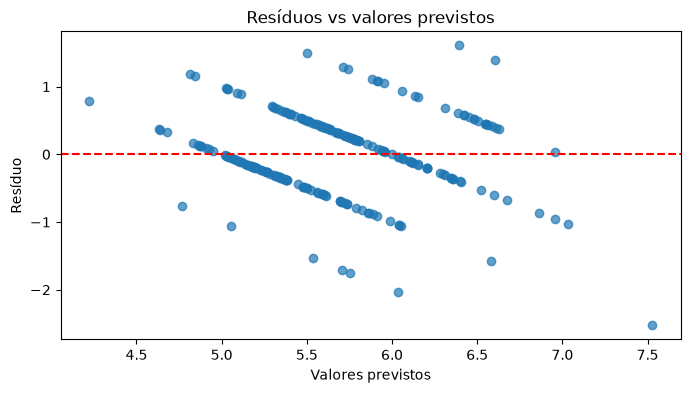

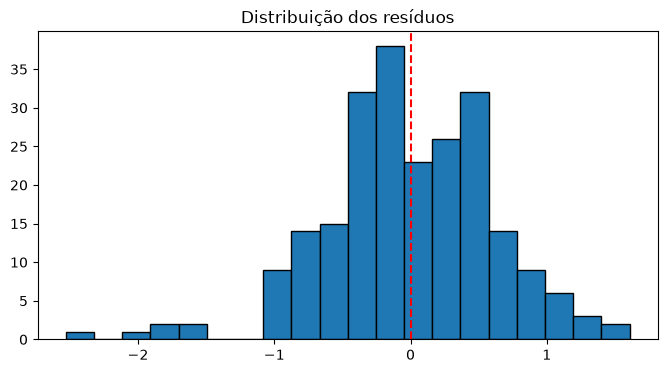

In [6]:
# Diagnóstico dos resíduos
residual = y_test - pred
print('residual_mean=', round(residual.mean(), 4))
print('residual_std=', round(residual.std(), 4))

plt.figure(figsize=(8, 4))
plt.scatter(pred, residual, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Valores previstos')
plt.ylabel('Resíduo')
plt.title('Resíduos vs valores previstos')
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(residual, bins=20, edgecolor='black')
plt.axvline(0, color='red', linestyle='--')
plt.title('Distribuição dos resíduos')
plt.show()


# Interpretação
#
# O modelo linear permite mensurar a relação média entre features físicas/químicas e a nota contínua.
# Em geral, o R² fica moderado e os resíduos não são perfeitamente homogêneos, o que sugere que
# o problema não é estritamente linear e que modelos mais flexíveis podem funcionar melhor.
#
# Conclusão prática: a regressão linear é útil como teste de diagnóstico, mas não é a melhor escolha
# para a classificação binária principal de qualidade do vinho.
